# Stable Diffusion 실습 — 직접 해보기

과제 원본 코드(`8-1. Stable diffusion 실습 (1).ipynb`)를 **흐름 단위로 묶어** 놓았다.
한 흐름을 끝까지 실행한 뒤, 그 아래 **✍️ 내 코멘트** 칸에 무엇을 했고 무엇을 알게 됐는지 적는다.

흐름마다 붙어 있는 칸
- **📖 코드 설명**: 코드가 무슨 일을 하는지
- **💡 생각해 볼 점**: 코드 리뷰할 때 짚어 볼 만한 부분 (원본 코드의 특이점, 개선할 여지)
- **✍️ 내 코멘트**: 직접 작성

**실행 전 확인 (코랩)**
- 메뉴 **런타임 → 런타임 유형 변경**에서 **GPU**를 고른다. 원본은 float16으로 모델을 올리므로 GPU가 있어야 한다.
- 모델 파일(수 GB)은 Hugging Face에서 받아 코랩 서버에 저장된다. 런타임이 끊기면 다시 받는다.
- 코드는 원본 그대로다. 코랩에서 그대로 안 되는 줄만 `# 📄 원본`과 `# ☁️ 코랩용`을 나란히 적었다.
- 원본에 없는 셀은 첫 줄에 `🧪 [개인 실험]`이라고 표시했다(흐름 3 아래 3개, 흐름 5 아래 1개).
- 처음 실행할 때는 모델 파일을 받느라 시간이 걸린다(Stable Diffusion v1.5, SD2 Inpainting, 개인 실험용 CLIP·Faster R-CNN).

## 🗺️ 전체 흐름 한눈에

| 파트 | 흐름 | 하는 일 |
|---|---|---|
| A. 환경 준비 | 1\~2 | 라이브러리 버전 확인 → GPU 확인, 이미지 표시 함수 |
| B. 글로 이미지 만들기 | 3 | Text-to-Image: 프롬프트만으로 새 이미지 생성 → 🧪 스텝 수·guidance·시드 실험 |
| C. 이미지 일부만 다시 그리기 | 4\~5 | Inpainting: 마스크(흰색) 부분만 프롬프트대로 다시 그림 (회색 배경 → 실제 사진) |

**Stable Diffusion이 이미지를 만드는 방식**

```
프롬프트 ─▶ 텍스트 인코더(CLIP) ─▶ 글의 의미 벡터
                                        │ (조건)
무작위 노이즈(잠재 공간 64×64) ─▶ U-Net이 노이즈를 조금씩 걷어 냄 × num_inference_steps
                                        │
                                  VAE 디코더 ─▶ 512×512 이미지
```

- 픽셀(512×512)이 아니라 **잠재 공간**(VAE로 줄인 64×64)에서 노이즈를 걷어 내서 빠르다(Latent Diffusion).
- `guidance_scale`: 프롬프트를 얼마나 강하게 따를지. 크면 프롬프트에 충실하지만 지나치면 색이 뭉개진다.
- `negative_prompt`: "이런 모습은 피해라"는 조건.
- **Inpainting**은 원본 이미지와 마스크를 함께 받아, 마스크의 **흰색 부분만** 다시 그린다(다만 사진 전체를 압축했다가 복원하므로 마스크 밖의 세밀한 부분도 조금 바뀐다. 흐름 5 개인 실험 참고). 제조 현장에서는 정상 제품 사진에 결함을 그려 넣어 **부족한 불량 데이터를 늘리는 데** 쓸 수 있다.

# 파트 A. 환경 준비

## 흐름 1. 라이브러리 설치와 버전 확인
Stable Diffusion을 쓰는 `diffusers`와 텍스트 인코더를 담은 `transformers`의 버전을 확인한다.

**📖 코드 설명**
- `diffusers`: Hugging Face의 확산 모델 라이브러리. `StableDiffusionPipeline` 한 줄로 텍스트 인코더·U-Net·VAE·스케줄러를 한꺼번에 불러온다.
- `transformers`: 프롬프트를 벡터로 바꾸는 CLIP 텍스트 인코더가 여기에 있다.
- 원본은 설치 줄이 모두 주석이다. 원본 출력의 버전은 diffusers `0.33.1`, transformers `4.52.4`이고, 세 번째 셀이 그 버전으로 맞추는 명령(역시 주석)이다.

In [ ]:
# !pip install diffusers transformers accelerate torch torchvision

In [ ]:
import diffusers
import transformers

diffusers.__version__

'0.40.0'

In [ ]:
transformers.__version__

'5.18.0'

In [ ]:
# !pip install diffusers==0.33.1
# !pip install transformers==4.52.4

**💡 생각해 볼 점**
- 설치 줄이 모두 주석이지만 코랩에는 `diffusers`와 `transformers`가 이미 깔려 있어 그대로 돌아갔다.
- 버전은 원본과 다르다. 원본은 diffusers `0.33.1`, transformers `4.52.4`인데 코랩은 `0.40.0`, `5.18.0`이다. 그래서 흐름 3부터 `torch_dtype is deprecated ... Please use dtype instead` 경고가 뜬다(경고일 뿐 실행은 된다).
- 원본 출력의 `accelerate was not found` 경고는 코랩에서 뜨지 않았다. 코랩에는 `accelerate`가 깔려 있기 때문이다.

> ✍️ **내 코멘트**
>
> 설치 없이 코랩 기본 라이브러리로 돌아갔지만 버전이 원본보다 높아서 경고 문구가 달라졌다. 원본과 똑같이 맞추려면 세 번째 셀의 버전 고정 명령을 풀어야 한다.

## 흐름 2. GPU 확인과 이미지 표시 함수
GPU가 있으면 `cuda`, 없으면 `cpu`를 쓰고, 생성한 이미지를 화면에 그리는 함수를 만든다.

**📖 코드 설명**
- `device`: 뒤의 모든 셀이 이 값으로 모델을 올린다.
- `display_image`: PIL 이미지를 matplotlib로 축 없이 그린다.
- `StableDiffusionInpaintPipeline`도 여기서 미리 import한다(흐름 4에서 사용).

In [1]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

**💡 생각해 볼 점**
- `display_image`는 `plt.imshow`에 색 지도(`cmap`)를 주지 않아서, 흑백(`L`) 마스크가 흰색/검은색이 아니라 **노란색/보라색**으로 보인다(흐름 4·5의 마스크 그림). `cmap='gray'`를 주면 실제 색대로 보인다.

> ✍️ **내 코멘트**
>
> GPU(`cuda`)를 잡았고, 이미지 표시 함수를 만들었다. 마스크가 노란색/보라색으로 보이는 건 실제 색이 아니라 matplotlib 기본 색 지도 때문이다.

# 파트 B. 글로 이미지 만들기 (Text-to-Image)

## 흐름 3. Stable Diffusion v1.5로 이미지 생성
프롬프트 한 줄로 새 이미지를 만들고 `generated_defect_0.png`로 저장한다.

**📖 코드 설명**
- **1.1 파이프라인 로드**: `runwayml/stable-diffusion-v1-5`를 `float16`(절반 정밀도)으로 받아 GPU에 올린다. 메모리를 절반 정도로 줄인다.
- **1.2 생성**
  - `prompt_defect`: 만들 이미지 설명 ("우주복을 입고 달에서 말을 타는 사람")
  - `negative_prompt`: 피할 모습 (흐릿함, 기형, 만화, 그림 등)
  - `num_inference_steps=30`: 노이즈를 걷어 내는 횟수. 많을수록 정교하지만 느리다.
  - `guidance_scale=8.5`: 프롬프트를 따르는 강도
- **1.3 저장**: 생성한 이미지를 그리고 PNG로 저장한다.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


  0%|          | 0/30 [00:00<?, ?it/s]

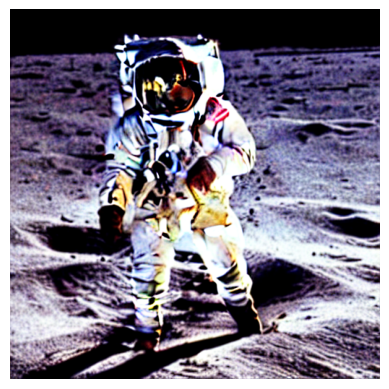

Image saved as generated_defect_0.png


In [ ]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)

with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images

# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


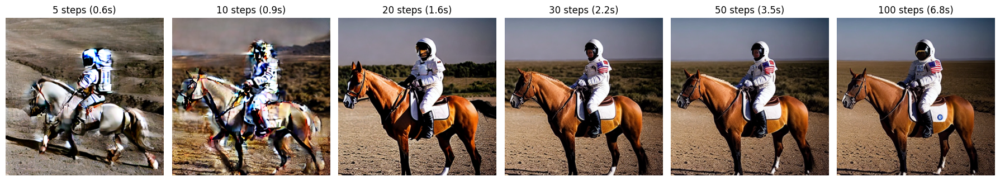

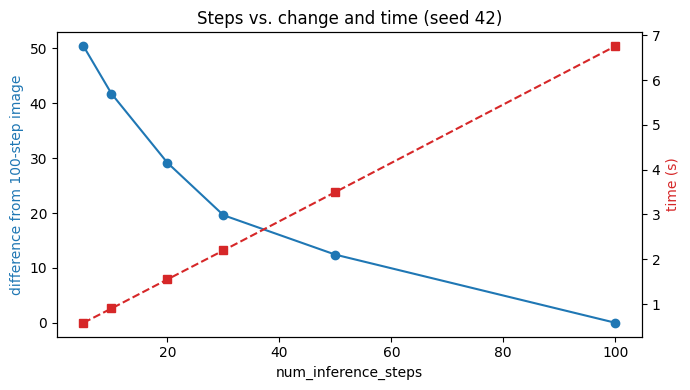

   5 steps | 100스텝 그림과의 차이  50.41 |  0.58초
  10 steps | 100스텝 그림과의 차이  41.75 |  0.90초
  20 steps | 100스텝 그림과의 차이  29.15 |  1.55초
  30 steps | 100스텝 그림과의 차이  19.60 |  2.20초
  50 steps | 100스텝 그림과의 차이  12.41 |  3.50초
 100 steps | 100스텝 그림과의 차이   0.00 |  6.76초


In [ ]:
# 🧪 [개인 실험] 원본에 없는 셀: 원본은 30스텝인데, 몇 스텝부터는 더 늘려도 그림이 거의 안 바뀌고 시간만 늘어나는지 궁금했다
import time
import numpy as np

pipe_text2img.set_progress_bar_config(disable=True)  # 진행 막대가 너무 많이 떠서 실험 동안 끈다
steps_list = [5, 10, 20, 30, 50, 100]
step_images, step_times = [], []
for steps in steps_list:
    generator = torch.Generator(device=device).manual_seed(42)  # 시드를 고정해 스텝 수만 달라지게 한다
    torch.cuda.synchronize()
    start = time.time()
    with torch.autocast("cuda"):
        image = pipe_text2img(prompt_defect, negative_prompt=negative_prompt,
                              num_inference_steps=steps, guidance_scale=guidance_scale_val,
                              generator=generator).images[0]
    torch.cuda.synchronize()
    step_times.append(time.time() - start)
    step_images.append(image)

# 가장 많이 돌린 100스텝 그림을 기준으로, 각 그림이 얼마나 다른지 (픽셀 평균 절대 차이, 0~255)
reference = np.asarray(step_images[-1]).astype(np.float32)
step_diffs = [np.abs(np.asarray(img).astype(np.float32) - reference).mean() for img in step_images]

fig, axes = plt.subplots(1, len(steps_list), figsize=(3 * len(steps_list), 3.4))
for ax, img, steps, t in zip(axes, step_images, steps_list, step_times):
    ax.imshow(img)
    ax.set_title(f"{steps} steps ({t:.1f}s)")
    ax.axis('off')
plt.tight_layout()
plt.show()

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(steps_list, step_diffs, 'o-', color='tab:blue')
ax1.set_xlabel('num_inference_steps')
ax1.set_ylabel('difference from 100-step image', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(steps_list, step_times, 's--', color='tab:red')
ax2.set_ylabel('time (s)', color='tab:red')
plt.title('Steps vs. change and time (seed 42)')
plt.tight_layout()
plt.show()

for steps, d, t in zip(steps_list, step_diffs, step_times):
    print(f"{steps:4d} steps | 100스텝 그림과의 차이 {d:6.2f} | {t:5.2f}초")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

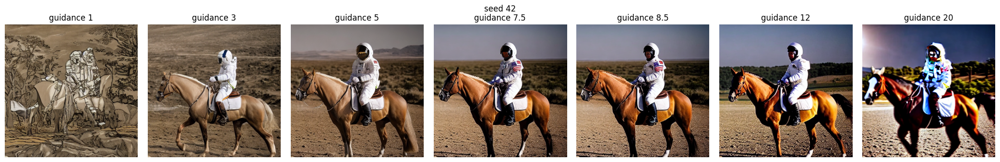

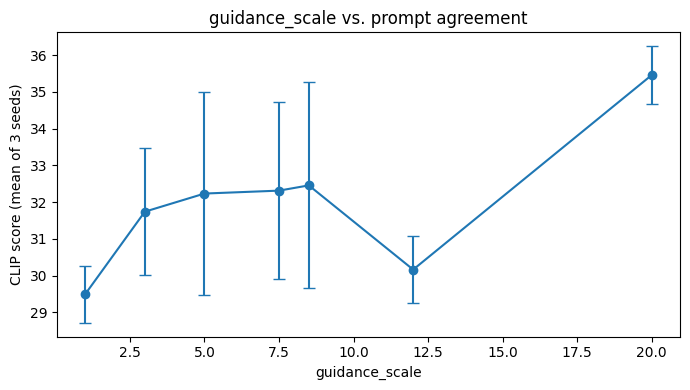

guidance    1 | CLIP 점수 평균 29.50 ± 0.78 | 시드별 [28.51, 30.41, 29.57]
guidance    3 | CLIP 점수 평균 31.74 ± 1.73 | 시드별 [34.04, 31.32, 29.86]
guidance    5 | CLIP 점수 평균 32.23 ± 2.76 | 시드별 [36.08, 29.74, 30.88]
guidance  7.5 | CLIP 점수 평균 32.31 ± 2.41 | 시드별 [35.73, 30.66, 30.56]
guidance  8.5 | CLIP 점수 평균 32.46 ± 2.80 | 시드별 [36.41, 30.62, 30.33]
guidance   12 | CLIP 점수 평균 30.17 ± 0.91 | 시드별 [31.21, 28.99, 30.29]
guidance   20 | CLIP 점수 평균 35.45 ± 0.79 | 시드별 [36.2, 34.37, 35.8]


In [ ]:
# 🧪 [개인 실험] 원본에 없는 셀: guidance_scale을 바꾸면 그림이 프롬프트를 얼마나 따르는지 숫자로 보고 싶었다
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def to_embedding(output):
    return output if torch.is_tensor(output) else output.pooler_output  # 라이브러리 버전에 따라 반환 형태가 다르다

def clip_score(images, text):
    """그림과 문장의 CLIP 코사인 유사도 × 100 (높을수록 그림이 문장과 잘 맞는다)"""
    inputs = clip_processor(text=[text], images=images, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        image_emb = to_embedding(clip_model.get_image_features(pixel_values=inputs["pixel_values"]))
        text_emb = to_embedding(clip_model.get_text_features(input_ids=inputs["input_ids"],
                                                             attention_mask=inputs["attention_mask"]))
    image_emb = image_emb / image_emb.norm(dim=-1, keepdim=True)
    text_emb = text_emb / text_emb.norm(dim=-1, keepdim=True)
    return (image_emb @ text_emb.T).squeeze(-1).mul(100).tolist()

guidance_list = [1, 3, 5, 7.5, 8.5, 12, 20]
guidance_seeds = [42, 7, 123]  # 한 장만 보면 우연일 수 있어서 시드 3개의 평균을 본다
guidance_images = {}   # (guidance, seed) -> 그림
guidance_scores = {}   # guidance -> 시드별 CLIP 점수
for g in guidance_list:
    imgs = []
    for seed in guidance_seeds:
        generator = torch.Generator(device=device).manual_seed(seed)
        with torch.autocast("cuda"):
            image = pipe_text2img(prompt_defect, negative_prompt=negative_prompt,
                                  num_inference_steps=num_steps, guidance_scale=g,
                                  generator=generator).images[0]
        guidance_images[(g, seed)] = image
        imgs.append(image)
    guidance_scores[g] = clip_score(imgs, prompt_defect)

fig, axes = plt.subplots(1, len(guidance_list), figsize=(3 * len(guidance_list), 3.4))
for ax, g in zip(axes, guidance_list):
    ax.imshow(guidance_images[(g, 42)])
    ax.set_title(f"guidance {g}")
    ax.axis('off')
plt.suptitle('seed 42')
plt.tight_layout()
plt.show()

means = [np.mean(guidance_scores[g]) for g in guidance_list]
stds = [np.std(guidance_scores[g]) for g in guidance_list]
plt.figure(figsize=(7, 4))
plt.errorbar(guidance_list, means, yerr=stds, fmt='o-', capsize=4)
plt.xlabel('guidance_scale')
plt.ylabel('CLIP score (mean of 3 seeds)')
plt.title('guidance_scale vs. prompt agreement')
plt.tight_layout()
plt.show()

for g, m, s in zip(guidance_list, means, stds):
    print(f"guidance {g:4} | CLIP 점수 평균 {m:5.2f} ± {s:4.2f} | 시드별 {[round(x, 2) for x in guidance_scores[g]]}")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 188MB/s]


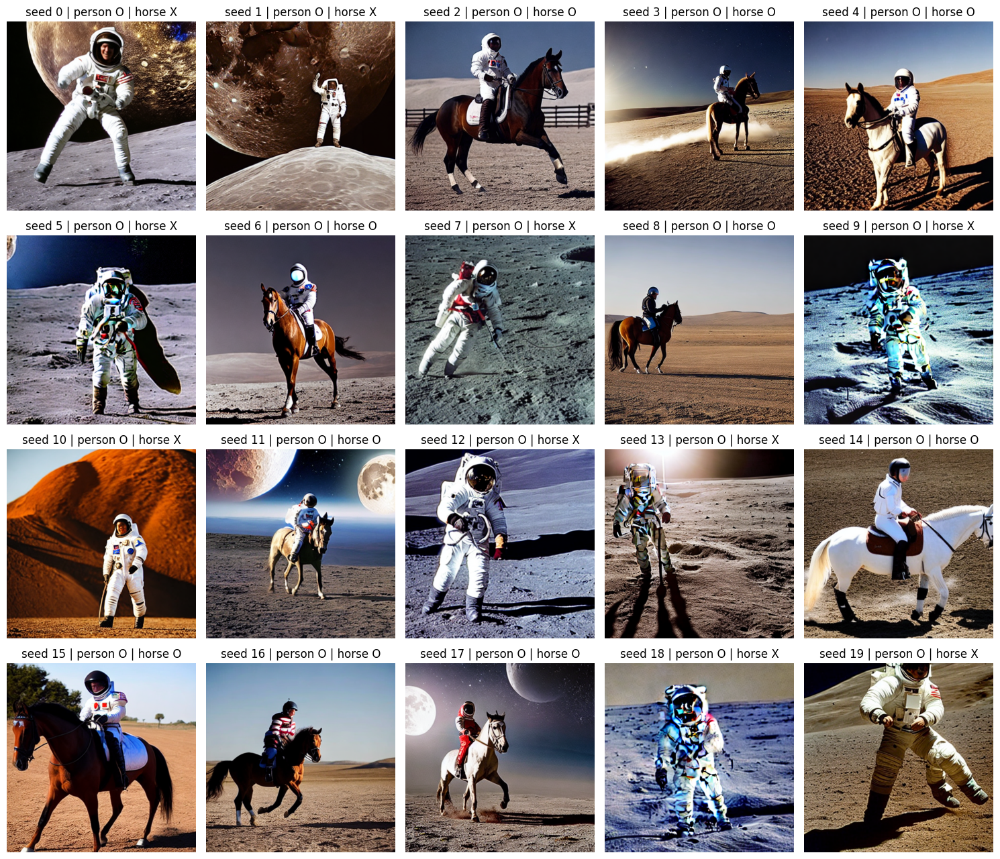

시드 20개 중 사람 20장, 말 10장, 사람과 말이 함께 10장


In [ ]:
# 🧪 [개인 실험] 원본에 없는 셀: 흐름 3 그림에 말이 빠진 게 그 한 장만의 우연인지, 시드를 바꿔도 그런지 궁금했다
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
import torchvision.transforms.functional as TF

# 사람 눈 대신 COCO로 학습된 물체 탐지 모델로 '사람'과 '말'이 있는지 판정한다
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
detector = fasterrcnn_resnet50_fpn_v2(weights=weights).to(device).eval()
coco_names = weights.meta["categories"]

def detect(image, threshold=0.5):
    with torch.no_grad():
        out = detector([TF.to_tensor(image).to(device)])[0]
    return {coco_names[label] for label, score in zip(out["labels"].tolist(), out["scores"].tolist()) if score >= threshold}

seeds = list(range(20))
seed_images, seed_found = [], []
for seed in seeds:
    generator = torch.Generator(device=device).manual_seed(seed)
    with torch.autocast("cuda"):
        image = pipe_text2img(prompt_defect, negative_prompt=negative_prompt,
                              num_inference_steps=num_steps, guidance_scale=guidance_scale_val,
                              generator=generator).images[0]
    seed_images.append(image)
    seed_found.append(detect(image))

fig, axes = plt.subplots(4, 5, figsize=(15, 13))
for ax, seed, img, found in zip(axes.flat, seeds, seed_images, seed_found):
    ax.imshow(img)
    ax.set_title(f"seed {seed} | person {'O' if 'person' in found else 'X'} | horse {'O' if 'horse' in found else 'X'}")
    ax.axis('off')
plt.tight_layout()
plt.show()

n_person = sum('person' in f for f in seed_found)
n_horse = sum('horse' in f for f in seed_found)
n_both = sum({'person', 'horse'} <= f for f in seed_found)
print(f"시드 {len(seeds)}개 중 사람 {n_person}장, 말 {n_horse}장, 사람과 말이 함께 {n_both}장")

pipe_text2img.set_progress_bar_config(disable=False)  # 실험 동안 껐던 진행 막대를 다시 켠다

**💡 생각해 볼 점**
- 로드 진행 막대에 **구성 요소 7개**(텍스트 인코더·토크나이저·U-Net·VAE·스케줄러·안전 검사기·특징 추출기)가 보인다. 하나의 모델이 아니라 여러 모델을 묶은 파이프라인이다.
- 30스텝 생성이 L4에서 **2초**(15.14 it/s) 걸렸다. 잠재 공간에서 계산해서 빠르다.
- 결과에 우주복을 입은 사람과 달 표면은 나왔지만 **말은 보이지 않는다**.
- `generator`를 만들어 놓고 `# generator=generator`로 주석 처리해서 시드가 고정되지 않는다. 실행할 때마다 그림이 달라지고, 원본 출력과도 다르다. 아래 개인 실험처럼 비교하려면 시드를 꼭 고정해야 한다.
- 변수 이름(`prompt_defect`)과 부정 프롬프트(`normal, no defect`)는 결함 이미지용인데 프롬프트는 우주인 그림이다. 결함 생성 코드를 데모용으로 바꾸면서 일부만 고친 것으로 보인다.
- 파이프라인이 이미 float16이라 `torch.autocast("cuda")`는 없어도 된다. 또 CPU에서는 float16으로 올린 모델이 제대로 돌지 않아서, 이 셀은 GPU 전용이다(흐름 5는 CPU일 때 float32로 처리한다).

**🧪 스텝 수 (개인 실험 ①, 시드 42)**: 원본의 30스텝이 적당한지 5\~100스텝으로 비교했다.

| 스텝 | 5 | 10 | 20 | 30 | 50 | 100 |
|---|---|---|---|---|---|---|
| 걸린 시간 | 0.58초 | 0.90초 | 1.55초 | 2.20초 | 3.50초 | 6.76초 |
| 100스텝 그림과의 차이 | 50.41 | 41.75 | 29.15 | 19.60 | 12.41 | 0 |

- 5·10스텝은 흐릿하고 얼룩이 남았다. **20스텝부터** 말과 우주인의 자세·배경이 정해지고, 그 뒤로는 국기·배지 같은 작은 부분만 바뀐다. 시간은 스텝 수에 거의 정비례한다(100스텝은 30스텝의 약 3배).
- 픽셀 차이는 20스텝 뒤에도 계속 줄어든다. 작은 부분이 조금만 바뀌어도 픽셀 차이에는 잡히기 때문이라, 숫자만 보지 않고 그림과 같이 봐야 한다.
- **왜**: 학습 때 1,000단계에 걸쳐 섞은 노이즈를, 생성할 때는 `num_inference_steps`번으로 **건너뛰며** 걷어 낸다(간격은 스케줄러가 정함). 스텝이 적으면 한 번에 크게 건너뛰어서 노이즈가 남는다. 또 노이즈가 많은 **앞쪽 스텝에서 큰 구도**가, 노이즈가 적은 **뒤쪽 스텝에서 세부**가 정해져서, 20스텝쯤 구도가 굳으면 그 뒤로는 세부만 바뀐다. 스텝마다 U-Net을 같은 횟수만큼 돌려서 시간은 스텝 수에 비례한다.
- 결론: 이 프롬프트에서는 **20\~30스텝**이 sweet spot이다. 원본의 30스텝은 적당하고, 50·100스텝은 시간만 더 든다.

**🧪 guidance_scale (개인 실험 ②, 시드 3개 평균)**: CLIP 점수(그림과 프롬프트의 의미가 얼마나 비슷한지)로 비교했다.

| guidance | 1 | 3 | 5 | 7.5 | 8.5 | 12 | 20 |
|---|---|---|---|---|---|---|---|
| CLIP 점수 | 29.50 ± 0.78 | 31.74 ± 1.73 | 32.23 ± 2.76 | 32.31 ± 2.41 | 32.46 ± 2.80 | 30.17 ± 0.91 | 35.45 ± 0.79 |

- **1**: 사진이 아니라 연필 그림 같은 모습이고, 말과 사람의 형태도 흐릿하다. 점수도 가장 낮다.
- **3\~12**: 모두 말을 탄 우주인 사진으로 비슷하다. 3\~8.5는 점수 차이가 최대 0.72로, 시드에 따른 흔들림(±1.73\~2.80)보다 작다. 12는 2점쯤 낮지만 이것도 흔들림 범위 안이라, 이 범위 안에서는 어느 값이 낫다고 말할 수 없다.
- **20**: 색이 지나치게 진하고 흐릿하게 뭉개졌는데도 **점수는 가장 높다**. CLIP 점수는 프롬프트의 내용이 들어 있는지만 보고 그림의 품질은 보지 않기 때문이다. 점수 하나만 보고 20을 고르면 틀린 결론이 된다.
- **왜 (Classifier-Free Guidance)**: 스텝마다 노이즈를 프롬프트로 한 번, 부정 프롬프트(없으면 빈 문장)로 한 번 예측하고 그 차이를 키운다. `예측 노이즈 = 부정 예측 + guidance × (프롬프트 예측 − 부정 예측)`. guidance가 1이면 프롬프트 예측만 쓰는 셈이라 끌어당기는 힘이 없고, diffusers는 부정 프롬프트 계산도 건너뛴다. 그래서 `cartoon, painting, illustration`을 피하라는 조건이 빠져 그림 같은 결과가 나왔다. 너무 크면 차이를 지나치게 키워 값이 모델이 학습한 범위를 벗어나서, 색이 과하게 진해지고 형태가 뭉개진다.
- 결론: 3\~12 사이면 충분하고, 원본의 8.5도 이 안에 있다.

**🧪 말이 빠진 이유 (개인 실험 ③, 시드 20개)**: 말이 있는지는 물체 탐지 모델(Faster R-CNN, COCO 학습)로 판정했다.

- **사람(우주인) 20장, 말 10장**으로 말은 딱 절반만 나왔다. 탐지 모델의 판정(말 O/X)은 그림을 직접 봐도 20장 모두 맞았다. 흐름 3에서 말이 빠진 건 **절반 확률로 일어나는 일**이었고, 한 장만 보고 "모델이 말을 못 그린다"고 하면 틀린 결론이다.
- 말이 없는 그림은 대부분 달 표면이고, 말이 있는 그림은 절반 넘게 흙바닥이나 사막이다. "달"과 "말 타기"를 **한 그림에 같이** 담는 건 잘 못한다.
- **왜**: 시드는 맨 처음 노이즈를 정하고, 실험 ①처럼 큰 구도는 앞쪽 스텝에서 그 노이즈로부터 정해진다. 그래서 시드가 바뀌면 말이 있는지부터 달라진다. 프롬프트를 읽는 CLIP 텍스트 인코더는 단어의 뜻은 잘 담지만 "누가 무엇을 탄다" 같은 **관계**는 약하게 담는다. 또 학습 데이터에는 "달 위의 우주인"과 "말 탄 사람" 사진은 많지만 둘이 합쳐진 사진은 거의 없어서, 모델은 둘 중 익숙한 장면 하나 쪽으로 그리기 쉽다.

> ✍️ **내 코멘트**
>
> 프롬프트 한 줄로 30스텝 그림을 2초 만에 만들었지만, 우주인만 나오고 말은 빠졌다. 교수님이 말씀하신 비교 설계와 믿을 수 있는 수치를 생각해서, AI가 제안한 실험 중 세 가지를 골라 시드를 고정하고 해 봤다. 스텝 수를 바꿔 보니 20스텝부터 구도가 정해지고 그 뒤로는 시간만 늘어서 20\~30스텝이면 충분했다. guidance는 1이면 연필 그림처럼, 20이면 색이 깨졌는데, CLIP 점수는 오히려 20이 가장 높았다. 숫자 하나만 보고 판단하면 틀린 결론을 낼 수 있다는 것을 직접 확인했다. 말이 빠진 것도 시드 20개로 다시 그려 보니 10장에만 말이 있어서, 절반 확률로 생기는 일이었다. 생성 모델은 시드를 고정하고 여러 장으로 판단해야 한다는 걸 알게 됐다.

# 파트 C. 이미지 일부만 다시 그리기 (Inpainting)

## 흐름 4. 회색 판에 "움푹 파인 자국" 그려 넣기
밝은 회색 배경 이미지의 가운데 원 부분에만 결함(찍힌 자국)을 그려 넣는다.

**📖 코드 설명**
- **2.1 로드**: Inpainting 전용 모델 `stabilityai/stable-diffusion-2-inpainting`을 불러온다. 실패하면 `pipe_inpaint = None`으로 두고 건너뛴다.
- **2.2 이미지·마스크**
  - `init_image`: 512×512 밝은 회색 판 (정상 제품 표면 역할)
  - `mask_image`: 검은 바탕에 가운데 흰 원 (150\~350 픽셀). **흰색 = 다시 그릴 곳**, 검은색 = 그대로 둘 곳
- **2.3 생성**: "거친 가장자리의 깊은 원형 자국"을 프롬프트로, 50스텝, guidance 7.5
- **2.4 저장**: `inpainted_defect_0.png`

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Inpainting pipeline loaded.
Using placeholder initial image and mask.


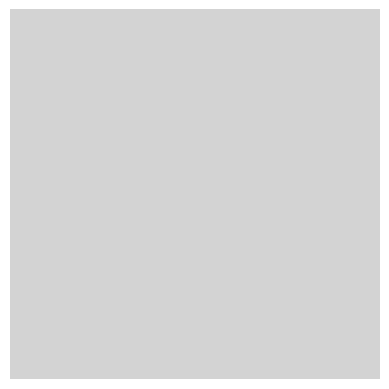

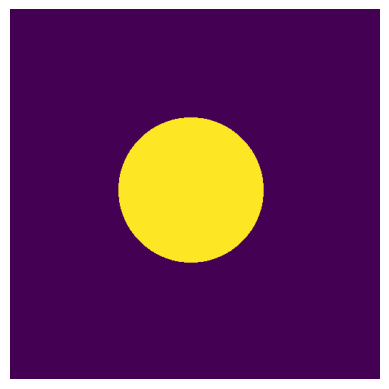

Inpainting with prompt: 'A deep circular dent with rough edges'


  0%|          | 0/50 [00:00<?, ?it/s]

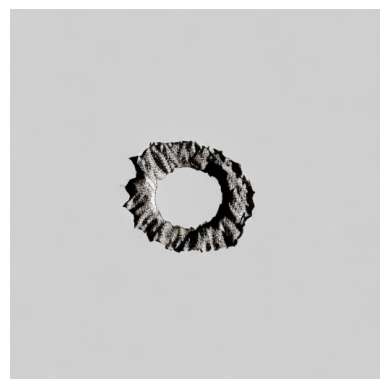

Image saved as inpainted_defect_0.png


In [ ]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
# 📄 원본: model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting" # 또는 다른 inpainting 모델
# ☁️ 코랩용: stabilityai 저장소가 Hugging Face에서 내려가(401 Repository Not Found) 같은 모델을 올려 둔 sd2-community 저장소로 바꿨다
model_id_inpaint = "sd2-community/stable-diffusion-2-inpainting" # 또는 다른 inpainting 모델
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16)
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리

if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.new("RGB", (512, 512), "lightgray") # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((150, 150), (350, 350)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)


    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "A deep circular dent with rough edges"
    negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images

    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

**💡 생각해 볼 점**
- 원본의 `stabilityai/stable-diffusion-2-inpainting`은 Hugging Face에서 내려가 `401 Repository Not Found`로 로드에 실패했다. `except`가 에러를 잡고 `pipe_inpaint = None`으로 넘어가서, **에러는 나지 않고 이미지만 안 나온 채 끝난다**. 같은 모델을 올린 `sd2-community` 저장소로 바꿔 해결했다.
- 결과: 마스크 원 안에만 **가장자리가 거친 고리 모양 자국**이 생기고, 원 밖의 회색 판은 눈으로 봐서는 그대로다. 단색이라 압축했다가 복원해도 거의 바뀌지 않기 때문이다(흐름 5 개인 실험 참고). 다만 "깊게 파인 자국"이라기보다 테두리만 울퉁불퉁한 모양이다.
- 시드를 정하지 않아 실행할 때마다 자국 모양이 달라진다.
- `from PIL import ImageDraw`를 `if` 안에서 가져온다. 다른 import처럼 맨 위에 두는 게 깔끔하다.

> ✍️ **내 코멘트**
>
> 마스크의 흰색 부분에만 결함 자국이 그려지고 나머지는 그대로라, 정상 제품 사진에 불량을 넣어 데이터를 늘리는 데 쓸 수 있겠다. 모델 저장소가 사라지면 `try/except` 때문에 에러 없이 조용히 건너뛰니 출력을 꼭 확인해야 한다.

## 흐름 5. 실제 사진(해변)에 "모래에 묻힌 보물 상자" 그려 넣기
인터넷의 해변 사진을 받아 가운데 타원 부분에 보물 상자를 그려 넣는다. 흐름 4를 한 셀로 다시 정리한 버전이다.

**📖 코드 설명**
- 1\~3: 디바이스 설정, 제목을 붙일 수 있게 `display_image`를 **다시 정의**, Inpainting 파이프라인을 **다시 로드**한다. GPU가 없으면 `float32`로 올린다.
- 4: Unsplash 해변 사진을 받아 512×512로 줄인다. 받기에 실패하면 하늘(파랑)·모래(황토)·해(금색)를 직접 그린 그림으로 대신한다.
  - 마스크: 가운데 타원 `[106, 56, 406, 456]` (너비 300, 높이 400)
- 5\~6: "모래에 묻힌 보물 상자" 프롬프트, 시드 `1234` 고정, guidance 8.5, 50스텝. CPU일 때는 `autocast` 없이 실행한다.
- 7: `result_inpainted_0.png`로 저장

Using device: cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/544 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Inpainting pipeline loaded with sd2-community/stable-diffusion-2-inpainting.
Image loaded and resized to 512x512.


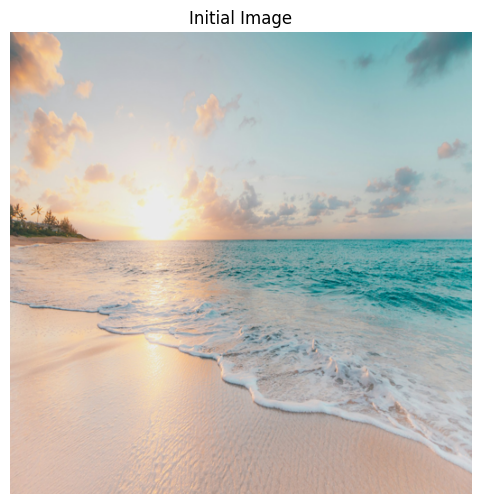

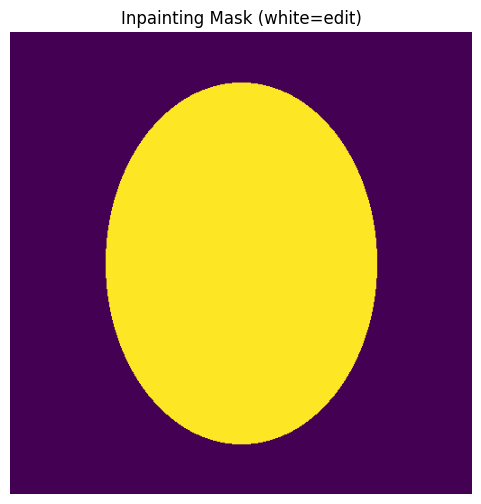

Running inpainting with prompt: A treasure chest buried in the sand


  0%|          | 0/50 [00:00<?, ?it/s]

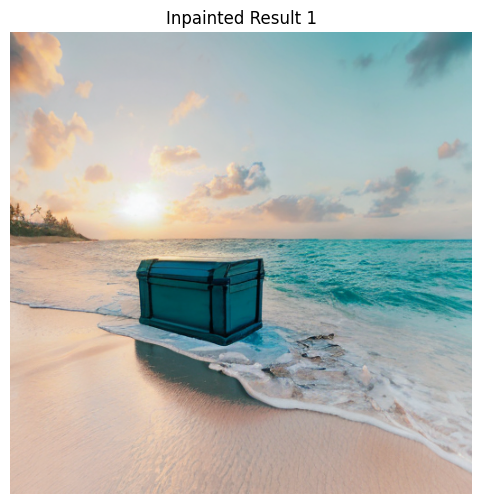

Saved: result_inpainted_0.png


In [3]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
# 📄 원본: model_id_inpaint = "stabilityai/stable-diffusion-2-inpainting"
# ☁️ 코랩용: stabilityai 저장소가 Hugging Face에서 내려가(401 Repository Not Found) 같은 모델을 올려 둔 sd2-community 저장소로 바꿨다
model_id_inpaint = "sd2-community/stable-diffusion-2-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [106, 56, 406, 456]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)

    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )

    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")


잠재 공간 크기: (1, 4, 64, 64) → 잠재 공간 한 칸이 원본 8×8 픽셀을 맡는다
인페인팅 결과      vs 원본 | 마스크 안 평균 차이  35.28 | 마스크 밖 평균 차이  3.90 | 마스크 밖에서 차이 20 넘는 픽셀 1.6%
VAE 압축·복원만   vs 원본 | 마스크 안 평균 차이   5.03 | 마스크 밖 평균 차이  3.50 | 마스크 밖에서 차이 20 넘는 픽셀 1.3%


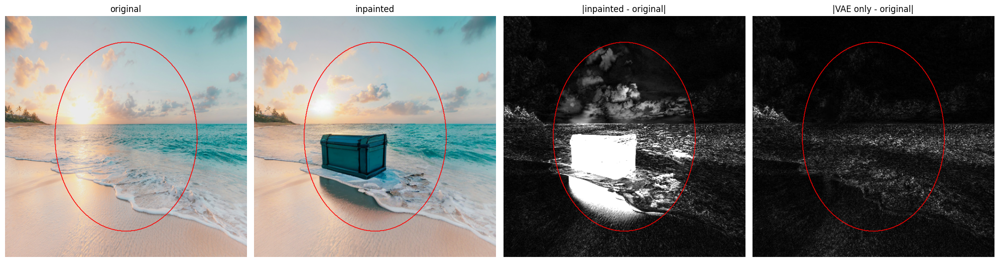

In [4]:
# 🧪 [개인 실험] 원본에 없는 셀: 마스크 밖(검은 부분)은 정말 그대로인지, 바뀐다면 왜 바뀌는지 숫자로 확인하고 싶었다
import numpy as np

init_np = np.asarray(init_image).astype(np.float32)
out_np = np.asarray(result.images[0].resize(init_image.size)).astype(np.float32)
mask_np = np.asarray(mask_image) > 127   # True = 다시 그린 곳(마스크 안)

# 생성은 하지 않고, 원본을 VAE로 압축했다가 복원만 해 본다
with torch.no_grad():
    x = pipe_inpaint.image_processor.preprocess(init_image).to(device, dtype=pipe_inpaint.vae.dtype)
    latent = pipe_inpaint.vae.encode(x).latent_dist.mean
    recon = pipe_inpaint.vae.decode(latent).sample
vae_np = np.asarray(pipe_inpaint.image_processor.postprocess(recon, output_type="pil")[0]).astype(np.float32)
print(f"잠재 공간 크기: {tuple(latent.shape)} → 잠재 공간 한 칸이 원본 {init_image.size[0] // latent.shape[-1]}×{init_image.size[1] // latent.shape[-2]} 픽셀을 맡는다")

diff_inpaint = np.abs(out_np - init_np).mean(-1)   # 픽셀마다 RGB 평균 차이 (0~255)
diff_vae = np.abs(vae_np - init_np).mean(-1)
for name, d in [("인페인팅 결과", diff_inpaint), ("VAE 압축·복원만", diff_vae)]:
    print(f"{name:12s} vs 원본 | 마스크 안 평균 차이 {d[mask_np].mean():6.2f} | 마스크 밖 평균 차이 {d[~mask_np].mean():5.2f} | 마스크 밖에서 차이 20 넘는 픽셀 {(d[~mask_np] > 20).mean():.1%}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5.4))
panels = [(init_np / 255, 'original'), (out_np / 255, 'inpainted'),
          (diff_inpaint, '|inpainted - original|'), (diff_vae, '|VAE only - original|')]
for ax, (img, title) in zip(axes, panels):
    if img.ndim == 2:
        ax.imshow(img, cmap='gray', vmin=0, vmax=60)   # 차이가 60 이상이면 흰색
    else:
        ax.imshow(img)
    ax.contour(mask_np, levels=[0.5], colors='red', linewidths=1)   # 빨간 선 = 마스크 경계
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

**💡 생각해 볼 점**
- 해변 사진의 타원 안에 **보물 상자**가 그려졌다. 하지만 "모래에 묻힌" 모습이 아니라 모래 위에 놓여 있고, 타원 안의 파도 모양도 함께 바뀌었다. 마스크 안은 프롬프트에 맞게 통째로 다시 그리기 때문이다.
- 시드를 `1234`로 고정해서(흐름 3·4와 달리) 다시 실행해도 같은 결과가 나온다.
- 흐름 4에서 이미 불러온 Inpainting 파이프라인을 **다시 로드**한다. 파일은 이미 받아 둬서 다시 받지는 않지만, 같은 모델을 한 번 더 읽어 GPU에 올린다. 이어서 실행할 때는 로드 부분을 빼도 된다.
- `resize((512, 512))`는 가로세로 비율을 무시해서, 정사각형이 아닌 사진은 찌그러진다.
- GPU/CPU 분기 때문에 같은 `pipe_inpaint(...)` 호출이 두 번 적혀 있다. 흐름 3과 달리 CPU에서도 돌아가게 만든 점은 좋다.

- **🧪 마스크 밖도 그대로일까 (개인 실험 ④)**: 원본과 결과의 픽셀 차이를 마스크 안과 밖으로 나눠 쟀다. 생성은 하지 않고 원본을 VAE로 압축했다가 복원만 한 그림과도 비교했다.

| 원본과 비교 (픽셀 평균 차이, 0\~255) | 마스크 안 | 마스크 밖 | 마스크 밖에서 차이 20 넘는 픽셀 |
|---|---|---|---|
| Inpainting 결과 | 35.28 | 3.90 | 1.6% |
| VAE 압축·복원만 | 5.03 | 3.50 | 1.3% |

- 마스크 밖도 **조금 바뀐다**(평균 3.90). 차이 그림을 보면 하늘·모래처럼 매끈한 곳은 거의 그대로이고, 야자수·파도 무늬처럼 **세밀한 곳만** 바뀌었다.
- 생성 없이 압축·복원만 해도 마스크 밖이 거의 같은 만큼(3.50), 같은 곳이 바뀐다. 마스크 밖 변화의 대부분은 Inpainting이 아니라 **VAE 압축** 때문이다.
- **왜**: Inpainting도 사진 전체를 잠재 공간(64×64)으로 줄였다가 다시 키운다. 잠재 공간 한 칸이 원본 **8×8 픽셀**을 맡아서, 그보다 작은 세부(글자, 가는 무늬)는 한 칸 안에 뭉개져 들어가 복원할 때 원래대로 돌아오지 않는다. 6장 AutoEncoder에서 "압축하면 세부가 사라진다"고 한 것과 같은 원리다.
- 실제 제품 사진에 결함을 넣으면 마스크 밖의 인쇄 글자나 작은 부품도 흐려질 수 있다. 마스크 밖은 원본 픽셀로 되돌려 붙이는 처리가 필요하다.

> ✍️ **내 코멘트**
>
> 실제 사진에도 마스크 부분만 바꿔 넣을 수 있었지만 상자는 묻히지 않고 모래 위에 놓였고, 재 보니 마스크 밖의 세밀한 부분도 VAE 압축 때문에 조금씩 바뀌었다. 생성은 장당 몇 초면 되지만(흐름 3 기준 2.2초) 원하는 그림이 절반만 나올 수 있어서, 결함 데이터로 쓰려면 더 만들고 골라내는 비용과 마스크 밖을 원본으로 되돌리는 처리까지 따져야 한다.